# 02. 데이터 엔지니어링 (인코딩·레이블링·스케일링)

| 항목 | 내용 |
|---|---|
| 목적 | 01 인과추론 결과를 반영해, 3~5단계(피해 예측·취약도 지수·지원금 최적화)가 바로 쓸 수 있는 **입력 테이블**을 만든다 |
| 입력 | `data/processed/model_daily_group` (eda_analysis 04단계 변수 79개), `causal_unit_effects`(01), `unit_profile`, `analysis_origin_group`, `analysis_daily_group`, `weather_climate`, `flow_region_month` |
| 출력 | `data/processed/features_daily.parquet` (일 × 지역 × 업종, 피해 예측용), `data/processed/unit_indicators.parquet` (지역 × 업종 30개, 취약도·최적화용), `references/feature_dictionary_cda.csv` (추가 변수 사전) |
| 브랜치 | `ana-engin` |

### 이 단계가 필요한가 — 필요하다
eda_analysis 04단계에서 기본 변수(기상 대표 변수·영업시간 강수 노출·달력·최근 매출 수준·인코딩)는 이미 만들었다. 그 위에 **01 인과추론에서 새로 확인한 것** 때문에 다음이 더 필요하다.

| 01에서 확인한 것 | 필요한 엔지니어링 | 쓰는 곳 |
|---|---|---|
| 호우가 중심 처치, 비 온 날 효과 + 이후 반등 여부 확인 필요 (3-2절) | 강한 비·보통 비의 **시차 변수(1~7일)**, 위약용 **선행 변수**, **호우 사건 ID** | 3단계 (Roth Tran 2023 기간 간 대체) |
| 폭염 효과는 휴가철 교란 (CH2) — 예측 모델은 주 고정효과를 쓸 수 없음 | **계절·연휴 레이블**(하계휴가 집중기, 연휴), 장기 매출 수준(roll14·roll28) | 3단계 (교란 대체 통제) |
| 시간대 강수(CH3)는 보류 | 일강수량·영업시간 강수 노출을 **둘 다 유지** | 3단계 (교차검증으로 선택) |
| 피해율은 지역·외지 의존이 키우고 규모와는 무관 (CH4·CH5) | 지역 × 강한 비, 외지 비중 × 강한 비 **상호작용**, 단위(30개) 인코딩 | 3단계 |
| 단위별 인과 효과·구조 특성 | **취약도 지표 후보 테이블**(민감도·노출·적응력), **피해 등급 레이블**, 지원 자격 레이블 | 4·5단계 |
| 6개월·월별 차이가 큰 기상 | **스케일링 원칙**(학습 구간에서만 맞춤), 구조 변수의 **누수 점검** | 3·4단계 |

**진행 순서**
1. 환경 설정·입력
2. 기상 시차·선행·사건 변수
3. 계절·연휴 레이블 — 교란 대체 통제
4. 상호작용·인코딩
5. 레이블링 — 단위 피해 등급·지원 자격
6. 스케일링 — 분포·시간 이동 점검과 원칙
7. 구조 변수의 누수 점검 (기간 안정성)
8. 취약도 지표 후보 테이블 (지역 × 업종)
9. 최종 점검·저장

## 1. 환경 설정·입력

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf
from scipy.stats import skew, spearmanr
from statsmodels.stats.outliers_influence import variance_inflation_factor

warnings.filterwarnings('ignore')
pd.set_option('display.max_columns', 60)
pd.set_option('display.width', 200)
pd.set_option('display.float_format', '{:,.3f}'.format)

ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
PROC = ROOT / 'data' / 'processed'
REF = ROOT / 'references'
load = lambda name: pd.read_parquet(PROC / f'{name}.parquet')

INK, INK2, GRID, SURFACE = '#0b0b0b', '#52514e', '#e4e3df', '#fcfcfb'
REGION_COLOR = {'강남구': '#2a78d6', '춘천시': '#eb6834'}
plt.rcParams.update({
    'font.family': 'Malgun Gothic', 'axes.unicode_minus': False, 'figure.dpi': 110,
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
    'axes.edgecolor': GRID, 'axes.labelcolor': INK2, 'xtick.color': INK2, 'ytick.color': INK2,
    'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.titlecolor': INK, 'axes.titlelocation': 'left',
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.6, 'axes.axisbelow': True,
    'axes.spines.top': False, 'axes.spines.right': False, 'legend.frameon': False,
})
REGIONS = ['강남구', '춘천시']
KEYS = ['region', 'industry_group']

base = load('model_daily_group')
causal = load('causal_unit_effects')
unit = load('unit_profile')
print(f"기본 테이블 model_daily_group {base.shape} (eda_analysis 04단계) | 01 인과 효과 {causal.shape} | unit_profile {unit.shape}")
NEW = {}   # 이 노트북에서 추가하는 변수 → (그룹, 설명)

기본 테이블 model_daily_group (5520, 79) (eda_analysis 04단계) | 01 인과 효과 (30, 27) | unit_profile (30, 17)


## 2. 기상 시차·선행·사건 변수

01의 이벤트 스터디(3-2절)에서 춘천은 **비 온 날만** 크게 감소하고 이후 0 근처로 돌아왔다. 3단계에서는 Roth Tran(2023)의 방법으로 '비 온 날 손실이 며칠 뒤 되돌아오는가(기간 간 대체)'를 정식으로 추정하므로, 그 재료를 만든다.

| 변수 | 정의 | 예측 입력 가능 여부 |
|---|---|---|
| `rain_heavy_lag1` ~ `lag7` | k일 전 강한 비(30mm↑) 여부 | 가능 (과거 값) |
| `rain_mid_lag1` ~ `lag7` | k일 전 보통 비(5~30mm) 여부 | 가능 |
| `rain_heavy_lead1` ~ `lead3` | k일 후 강한 비 여부 | **위약 검정 전용** (예측 입력 금지) |
| `days_since_heavy` | 마지막 강한 비 이후 경과일 (최대 8 = '8일 이상') | 가능 |
| `heavy_event_id` | 연속된 강한 비 날을 하나의 '호우 사건'으로 묶은 ID (없으면 결측) | 레이블 (사건 단위 분석·검증 분할) |

시차·선행은 **지역 단위 기상 테이블에서 만든 뒤** 업종에 붙인다 (업종별로 시프트하면 업종 수만큼 같은 값을 반복 계산할 뿐 결과는 같다).

In [2]:
w = (base.drop_duplicates(['date', 'region'])[['date', 'region', 'rain_sum', 'rain_heavy', 'rain_mid']]
         .sort_values(['region', 'date']).reset_index(drop=True))
gw = w.groupby('region')
for k in range(1, 8):
    w[f'rain_heavy_lag{k}'] = gw['rain_heavy'].shift(k)
    w[f'rain_mid_lag{k}'] = gw['rain_mid'].shift(k)
    NEW[f'rain_heavy_lag{k}'] = ('기상 시차', f'{k}일 전 강한 비(30mm↑)')
    NEW[f'rain_mid_lag{k}'] = ('기상 시차', f'{k}일 전 보통 비(5~30mm)')
for k in range(1, 4):
    w[f'rain_heavy_lead{k}'] = gw['rain_heavy'].shift(-k)
    NEW[f'rain_heavy_lead{k}'] = ('위약 전용', f'{k}일 후 강한 비 — 예측 입력 금지, 위약 검정용')

def days_since(flag, cap=8):
    out, run = [], cap
    for f in flag:
        run = 0 if f else min(run + 1, cap)
        out.append(run)
    return out

def event_ids(flag, region):
    out, eid, prev = [], 0, False
    for f in flag:
        if f and not prev:
            eid += 1
        out.append(f'{region[:2]}-H{eid:02d}' if f else None)
        prev = f
    return out

w['days_since_heavy'] = gw['rain_heavy'].transform(lambda s: days_since(s.values == 1))
w['heavy_event_id'] = pd.concat([pd.Series(event_ids(g['rain_heavy'].values == 1, r), index=g.index)
                                 for r, g in w.groupby('region')])
NEW['days_since_heavy'] = ('기상 시차', '마지막 강한 비 이후 경과일 (0 = 오늘, 최대 8)')
NEW['heavy_event_id'] = ('레이블', '연속 강한 비 날을 묶은 호우 사건 ID (예: 춘천-H03)')

ev = w.dropna(subset=['heavy_event_id']).groupby(['region', 'heavy_event_id']).agg(
    시작=('date', 'min'), 일수=('date', 'size'), 누적강수=('rain_sum', 'sum'))
print('호우 사건 요약 (지역별)')
display(ev.groupby('region').agg(사건수=('일수', 'size'), 강한비일=('일수', 'sum'), 최장일수=('일수', 'max'),
                                  사건당_평균강수=('누적강수', 'mean')).round(1))
lag_cols = [c for c in w.columns if c.startswith(('rain_heavy_l', 'rain_mid_lag', 'days_since', 'heavy_event'))]

호우 사건 요약 (지역별)


,사건수,강한비일,최장일수,사건당_평균강수
region,,,,
강남구,11,13,2,69.100
춘천시,14,17,2,61.100


- 강한 비 날(강남 13일·춘천 17일)은 **강남 11개·춘천 14개 사건**으로 묶인다 (최장 2일 연속). 3단계에서 '사건 단위로 검증 블록을 나누면' 같은 호우의 이틀이 학습·검증에 갈라지는 누수를 막을 수 있다.

## 3. 계절·연휴 레이블 — 교란 대체 통제

01(CH2)에서 폭염 효과는 **휴가철과 겹쳐** 인과 분리가 어려웠다. 인과 분석은 주 고정효과로 이를 막았지만, **예측 모델은 '내일'의 주 고정효과를 알 수 없다** (같은 주의 다른 날 매출이 필요). 그래서 예측 시점에 알 수 있는 값으로 계절 수준을 대신한다.

| 변수 | 정의 | 근거 |
|---|---|---|
| `roll14`, `roll28` | 직전 14·28일 log 매출 평균 (당일 제외) | 주보다 긴 계절 수준. lag7·roll7(기존)과 함께 |
| `summer_peak` | 하계휴가 집중기 7/25 ~ 8/10 | 국내 하계휴가는 통상 7월 말~8월 초에 몰린다 (달력 기반 사전 정의 레이블) |
| `long_holiday` | 휴일(주말·공휴일)이 4일 이상 이어진 연휴 기간 | 달력에서 자동 계산 (2025 추석 연휴) |
| `long_holiday_pre`, `long_holiday_post` | 연휴 직전 2일·직후 2일 | 연휴 전 장보기·연휴 후 반등 |

In [3]:
df = base.merge(w[['date', 'region'] + lag_cols], on=['date', 'region'], how='left', validate='many_to_one')
df = df.sort_values(KEYS + ['date']).reset_index(drop=True)
g = df.groupby(KEYS)['log_amt']
df['roll14'] = g.transform(lambda s: s.shift(1).rolling(14).mean())
df['roll28'] = g.transform(lambda s: s.shift(1).rolling(28).mean())
NEW['roll14'] = ('매출 수준', '직전 14일 log 매출 평균 (당일 제외)')
NEW['roll28'] = ('매출 수준', '직전 28일 log 매출 평균 (당일 제외)')

cal = df.drop_duplicates('date')[['date', 'is_offday']].sort_values('date').reset_index(drop=True)
run_id = (cal['is_offday'] != cal['is_offday'].shift()).cumsum()
run_len = cal.groupby(run_id)['is_offday'].transform('size')
cal['long_holiday'] = ((cal['is_offday'] == 1) & (run_len >= 4)).astype(int)
lh = cal['long_holiday'].values
cal['long_holiday_pre'] = [int(lh[i] == 0 and lh[i + 1:i + 3].any()) for i in range(len(cal))]
cal['long_holiday_post'] = [int(lh[i] == 0 and lh[max(i - 2, 0):i].any()) for i in range(len(cal))]
cal['summer_peak'] = cal['date'].between('2025-07-25', '2025-08-10').astype(int)
df = df.merge(cal.drop(columns='is_offday'), on='date', how='left')
for c, d in [('long_holiday', '휴일 4일 이상 연휴 기간'), ('long_holiday_pre', '연휴 직전 2일'),
             ('long_holiday_post', '연휴 직후 2일'), ('summer_peak', '하계휴가 집중기 7/25~8/10')]:
    NEW[c] = ('달력 레이블', d)
print('연휴 기간:', cal.loc[cal['long_holiday'] == 1, 'date'].dt.strftime('%m-%d').tolist())
print('하계휴가 집중기 일수:', cal['summer_peak'].sum(), '| 그중 폭염(체감 33℃↑) 일수(지역별):',
      df[df['summer_peak'] == 1].drop_duplicates(['date', 'region']).groupby('region')['heat_33'].sum().to_dict())

연휴 기간: ['10-03', '10-04', '10-05', '10-06', '10-07', '10-08', '10-09']


하계휴가 집중기 일수: 17 | 그중 폭염(체감 33℃↑) 일수(지역별): {'강남구': 10, '춘천시': 8}


### 3-1. 이 레이블이 폭염 교란을 얼마나 대신하나
업종 × 요일 효과를 통제한 풀링 회귀에서 폭염 계수가 **어떤 계절 통제를 넣느냐**에 따라 어떻게 바뀌는지 본다. 주 고정효과(01의 인과 기준선)에 가까워질수록 좋은 대체 통제다.

In [4]:
d = df[df['roll28'].notna()].copy()
d['unit'] = d['region'] + '|' + d['industry_group']
specs = {
    'ⓐ 요일만': '',
    'ⓑ + 최근 매출 수준(lag7·roll7)': ' + lag7 + roll7',
    'ⓒ + 장기 수준(roll28) + 계절·연휴 레이블': ' + lag7 + roll7 + roll28 + summer_peak + long_holiday + long_holiday_pre + long_holiday_post',
    'ⓓ 주 고정효과 (인과 기준선)': ' + C(unit):C(week)',
}
rows = []
for r in REGIONS:
    x = d[d['region'] == r]
    for name, extra in specs.items():
        f = f'log_amt ~ C(unit) + C(unit):C(dow_num) + is_holiday + heat_33 + rain_heavy + rain_mid{extra}'
        res = smf.ols(f, data=x).fit(cov_type='cluster', cov_kwds={'groups': x['date'].rank(method='dense').astype(int)})
        for t, lab in [('heat_33', '폭염 33℃↑'), ('rain_heavy', '강한 비')]:
            rows.append({'region': r, 'spec': name, 'term': lab, 'effect_pct': (np.exp(res.params[t]) - 1) * 100, 'p': res.pvalues[t]})
seas = pd.DataFrame(rows)
seas.pivot_table(index=['region', 'term'], columns='spec', values='effect_pct').round(2)[list(specs)]

spec            ⓐ 요일만  ⓑ + 최근 매출 수준(lag7·roll7)  ⓒ + 장기 수준(roll28) + 계절·연휴 레이블  ⓓ 주 고정효과 (인과 기준선)
region term                                                                                      
강남구    강한 비    -5.970                    -2.930                         -3.810             -0.440
       폭염 33℃↑  2.260                     2.170                          4.030              6.180
춘천시    강한 비    -8.350                    -7.320                         -9.100             -8.300
       폭염 33℃↑  1.860                    -0.130                          0.240             -2.030

- **춘천 강한 비**는 어떤 통제에서도 −7 ~ −9%로 주 고정효과 기준선(−8.3%)과 비슷하다. 춘천 호우 효과는 계절 통제 방식에 둔감하다.
- **강남 강한 비**는 요일만 통제하면 −6.0%, 최근·장기 매출 수준과 계절 레이블을 넣어도 −2.9 ~ −3.8%로, 주 고정효과 기준선(−0.4%)까지 내려오지 않는다. 즉 **예측 시점에 알 수 있는 변수만으로는 강남의 계절 교란을 다 걷어내지 못한다.** eda_analysis 05단계에서 예측 모델의 강남 피해율(−4.1%)이 인과 추정(−0.4%)보다 컸던 이유와 같다.
- 폭염은 통제 방식에 따라 부호·크기가 흔들린다 (강남 +2 ~ +6%, 춘천 −2 ~ +2%) — 01 CH2의 결론(폭염 효과는 인과로 해석하지 않음)과 맞다.
- → 3단계 예측 모델은 ⓒ의 변수 묶음을 계절 대체 통제로 쓰되, **예측 피해를 01의 인과 추정치로 보정(교정)하는 단계**를 둔다. 특히 강남 피해는 예측값을 그대로 쓰면 과대 추정될 위험이 있다. 이 차이 자체가 '피해를 어떻게 재느냐에 따라 지원 판단이 달라진다'는 6단계 문제 발굴의 근거가 된다.

## 4. 상호작용·인코딩

| 종류 | 변수 | 이유 |
|---|---|---|
| 상호작용 (신규) | `rain_heavy_x_chuncheon`, `rain_heavy_x_outsider`, `rain_mid_x_chuncheon` | 01 CH4·CH5: 피해율은 지역(방문객 상권)·외지 의존에서 커진다 |
| 상호작용 (기존) | `rain_x_chuncheon`, `rain_x_outsider`, `heat_x_chuncheon`, `rain_heavy_x_offday` | eda_analysis 04단계 |
| 정수 코드 (신규) | `unit_code` (지역 × 업종 30개) | 트리 모델 범주형 입력, 단위별 계수 모델의 그룹 |
| 원-핫 (신규) | `wt_*` 기상 유형 6종 (기준 = 평상) | 선형 모델에서 유형별 효과 |
| 기존 유지 | `region_code`·`industry_code`(정수), `ind_*`(업종 원-핫, 기준 = 음식점), `is_chuncheon` | — |

- **목표 인코딩은 쓰지 않는다.** 범주 수가 작고(지역 2·업종 15·단위 30) 범주마다 184일 표본이 있어 원-핫·정수 코드로 충분하며, 목표 인코딩은 매출 정보를 입력에 새게 한다.
- 특보 수준(`*_alert`, 0/1/2)은 **순서형 그대로** 둔다 (기준 초과 정도에 순서가 있다).

In [5]:
df['rain_heavy_x_chuncheon'] = df['rain_heavy'] * df['is_chuncheon']
df['rain_mid_x_chuncheon'] = df['rain_mid'] * df['is_chuncheon']
df['rain_heavy_x_outsider'] = df['rain_heavy'] * df['outsider_share']
units = sorted((df['region'] + '|' + df['industry_group']).unique())
df['unit_code'] = (df['region'] + '|' + df['industry_group']).map({u: i for i, u in enumerate(units)})
wt = pd.get_dummies(df['weather_type'].astype(str), prefix='wt', dtype=int)
df = pd.concat([df, wt.drop(columns='wt_평상')], axis=1)
for c, dsc in [('rain_heavy_x_chuncheon', '강한 비 × 춘천'), ('rain_mid_x_chuncheon', '보통 비 × 춘천'),
               ('rain_heavy_x_outsider', '강한 비 × 외지 고객 비중'), ('unit_code', '지역 × 업종 정수 코드 (0~29)')]:
    NEW[c] = ('상호작용' if '_x_' in c else '인코딩', dsc)
for c in wt.columns.drop('wt_평상'):
    NEW[c] = ('인코딩', f"기상 유형 원-핫 ({c[3:]}, 기준 = 평상)")
print('unit_code 범주 수:', df['unit_code'].nunique(), '| 기상 유형 원-핫:', [c for c in df.columns if c.startswith('wt_')])

unit_code 범주 수: 30 | 기상 유형 원-핫: ['wt_강한 비', 'wt_눈', 'wt_비', 'wt_폭염', 'wt_한파']


## 5. 레이블링 — 단위 피해 등급·지원 자격

### 5-1. 단위 피해 등급 (01 인과 효과 기반)
3단계 '피해 분류 모델'과 4단계 지수 검증의 **참조 레이블**이다. 01의 단위별 강한 비 인과 효과(경험적 베이즈 축소)와 FDR q값으로 나눈다.

| 등급 | 기준 | 의미 |
|---|---|---|
| **확인된 피해** | 축소 효과 ≤ −5% 그리고 q < 0.10 | 우연이 아닌 큰 피해 |
| **피해 (경미·불확실)** | 축소 효과 < 0, 위 기준 미달 | 방향은 감소이나 크기·확실성 부족 |
| **영향 없음·증가** | 축소 효과 ≥ 0 | 지원 대상 아님 |

### 5-2. 지원 자격
- `eligible`: 소상공인 지원 취지에 맞는 업종 = **대형유통(백화점·대형마트·면세점·쇼핑몰) 제외** (eda_analysis 06단계와 같은 기준)

In [6]:
lab = causal[KEYS + ['eb_rain_heavy', 'q_rain_heavy', 'eff_rain_heavy']].copy()
lab['damage_class'] = np.select([(lab['eb_rain_heavy'] <= -5) & (lab['q_rain_heavy'] < 0.10), lab['eb_rain_heavy'] < 0],
                                ['확인된 피해', '피해(경미·불확실)'], '영향 없음·증가')
lab['damage_class_code'] = lab['damage_class'].map({'영향 없음·증가': 0, '피해(경미·불확실)': 1, '확인된 피해': 2})
lab['eligible'] = (lab['industry_group'] != '대형유통').astype(int)
display(pd.crosstab(lab['region'], lab['damage_class']).reindex(columns=['확인된 피해', '피해(경미·불확실)', '영향 없음·증가']))
print('확인된 피해:', ', '.join((lab.loc[lab['damage_class'] == '확인된 피해', 'region'].str[:2] + ' ' +
                               lab.loc[lab['damage_class'] == '확인된 피해', 'industry_group']).tolist()))
df = df.merge(lab[KEYS + ['damage_class_code', 'eligible']], on=KEYS, how='left')
NEW['damage_class_code'] = ('레이블', '단위 피해 등급 0 영향 없음·증가 / 1 경미·불확실 / 2 확인된 피해 (01 인과 효과)')
NEW['eligible'] = ('레이블', '지원 자격 (대형유통 = 0)')

damage_class,확인된 피해,피해(경미·불확실),영향 없음·증가
region,,,
강남구,2,8,5
춘천시,7,7,1


확인된 피해: 강남 간편식, 강남 식료품소매, 춘천 교통·자동차, 춘천 식료품소매, 춘천 여가·오락, 춘천 음식점, 춘천 의류·잡화, 춘천 카페·디저트, 춘천 편의점


## 6. 스케일링 — 분포·시간 이동 점검과 원칙

### 6-1. 치우친 분포 → log 변환
강수·적설·매출 규모는 대부분 0이거나 작은 값이고 일부만 매우 크다. 선형·LASSO 계열에서는 소수의 극단값이 계수를 좌우하므로 **log(1+x)**로 펴서 쓴다.

In [7]:
day = df.drop_duplicates(['date', 'region'])
checks = {'rain_sum (일강수량)': day['rain_sum'], 'rain_exposure (영업시간 강수)': df['rain_exposure'],
          'rain_prev (전날 강수)': day['rain_prev'], 'snow_new (신적설)': day['snow_new'],
          'sales_per_store_monthly (점포당 월매출)': unit['sales_per_store_monthly'],
          'base_daily_sales (기준일 매출)': unit['base_daily_sales']}
rows = []
for name, s in checks.items():
    s = s.dropna().astype(float)
    rows.append({'변수': name, '0 비율(%)': (s == 0).mean() * 100, '왜도(원값)': skew(s), '왜도(log1p)': skew(np.log1p(s)),
                 '최댓값 ÷ 중앙값(0 제외)': s.max() / s[s > 0].median()})
pd.DataFrame(rows).round(2)

,변수,0 비율(%),왜도(원값),왜도(log1p),최댓값 ÷ 중앙값(0 제외)
0,rain_sum (일강수량),65.220,3.510,1.580,14.730
1,rain_exposure (영업시간 강수),65.220,4.920,2.160,33.560
2,rain_prev (전날 강수),65.220,3.510,1.580,14.730
3,snow_new (신적설),97.830,12.540,10.370,5.820
4,sales_per_store_monthly (점포당 월매출),0.000,4.930,0.280,38.930
5,base_daily_sales (기준일 매출),0.000,2.320,0.120,20.890


- 강수·점포당 매출·기준일 매출은 log(1+x)로 왜도가 크게 줄어든다 (점포당 월매출 4.9 → 0.3).
- **신적설은 log를 써도 왜도가 10 이상**이다 (98%가 0). 연속값 대신 **눈 온 날 여부(`snow`, 0/1)**로 쓴다 — eda_analysis 04단계 선택과 같다.

### 6-2. 시간에 따른 분포 이동 — 스케일러는 학습 구간에서만 맞춘다
3단계는 날짜 순서대로 5개 블록으로 나눈 **블록 교차검증**을 쓴다. 7월과 12월은 기온 분포가 완전히 다르므로, 전체 기간으로 평균·표준편차를 구해 표준화하면 **검증 블록의 정보가 학습에 새어 들어간다.**

In [8]:
mdl = df[df['use_for_model']].copy()
mdl['block'] = pd.qcut(mdl['date'].rank(method='dense'), 5, labels=False)
cols = ['feels_like_max', 'temp_min', 'log_rain', 'log_rain_exposure', 'lag7', 'roll28']
blk = mdl.groupby('block')[cols].agg(['mean', 'std'])
period = mdl.groupby('block')['date'].agg(lambda s: f"{s.min():%m/%d}~{s.max():%m/%d}")
view = blk.xs('mean', axis=1, level=1).round(2)
view.insert(0, '기간', period)
print('블록별 평균 (날짜 순 5개 블록)')
display(view)

rows = []
for b in range(5):
    tr, te = mdl[mdl['block'] != b], mdl[mdl['block'] == b]
    for c in ['feels_like_max', 'temp_min']:
        mu_full, sd_full = mdl[c].mean(), mdl[c].std()
        mu_tr, sd_tr = tr[c].mean(), tr[c].std()
        rows.append({'검증 블록': f'{b} ({period[b]})', '변수': c,
                     '전체 기준 z 평균': ((te[c] - mu_full) / sd_full).mean(),
                     '학습 기준 z 평균': ((te[c] - mu_tr) / sd_tr).mean()})
pd.DataFrame(rows).pivot(index='검증 블록', columns='변수', values=['전체 기준 z 평균', '학습 기준 z 평균']).round(2)

블록별 평균 (날짜 순 5개 블록)


,기간,feels_like_max,temp_min,log_rain,log_rain_exposure,lag7,roll28
block,,,,,,,
0,07/15~08/17,31.900,23.940,1.100,0.600,20.410,20.410
1,08/18~09/20,30.100,22.240,1.250,0.620,20.380,20.390
2,09/21~10/24,22.390,14.970,0.960,0.490,20.360,20.380
3,10/25~11/27,14.530,3.530,0.190,0.090,20.410,20.400
4,11/28~12/31,3.880,-3.600,0.320,0.150,20.410,20.400


전체 기준 z 평균              학습 기준 z 평균         
변수              feels_like_max temp_min feels_like_max temp_min
검증 블록                                                          
0 (07/15~08/17)          1.030    1.040          1.350    1.360
1 (08/18~09/20)          0.870    0.890          1.080    1.120
2 (09/21~10/24)          0.170    0.240          0.190    0.280
3 (10/25~11/27)         -0.550   -0.770         -0.650   -0.950
4 (11/28~12/31)         -1.510   -1.400         -2.730   -2.260

- 체감온도 블록 평균은 7~8월 31.9℃에서 11월 말~12월 3.9℃로 내려간다. 마지막 블록(11/28~12/31)은 전체 기간 기준으로 표준화하면 평균 z = −1.5지만, 학습 구간 기준이면 −2.7이다 — 전체 기준으로 표준화하면 '검증 기간의 분포'를 미리 본 셈이 된다.

### 6-3. 스케일링 원칙 (3~5단계 공통)

| 모델·용도 | 스케일링 | 이유 |
|---|---|---|
| 트리(LightGBM) | **하지 않음** | 분기 기준은 순서만 본다 |
| OLS·고정효과 회귀 | **하지 않음** (log 변환만) | 계수를 원 단위(%, log 1단위)로 해석해야 한다 |
| LASSO·Ridge | `StandardScaler`를 **파이프라인 안에 넣어 학습 블록에서만 fit** | 벌점이 변수 크기에 좌우됨. 검증 블록 정보 누수 방지 |
| 이벤트 0/1 더미·특보 순서형 | 하지 않음 | 0/1·순서 의미 유지 |
| 취약도 지수 지표 (4단계) | **백분위·최소-최대·z점수를 모두 계산해 비교** | 변환 선택 자체가 지수 순위를 바꾸므로(Tate, 2012) 하나로 고정하지 않고 불확실성 분석의 한 단계로 둔다 |

따라서 이 단계에서는 **스케일링된 값을 저장하지 않는다.** 원값(+ log 변환)만 저장하고, 스케일링은 각 단계의 모델 파이프라인 안에서 한다.

## 7. 구조 변수의 누수 점검 — 기간을 나눠도 같은 값인가

외지 고객 비중·저녁 매출 비중·휴일/평일 비 같은 **구조 변수는 6개월 전체로 계산한 고정값**이다. 블록 교차검증에서 이 값에는 검증 기간의 매출이 일부 들어 있다. 기간을 앞(7~9월)·뒤(10~12월)로 나눠 계산해도 거의 같다면 누수의 영향은 무시할 수 있다.

In [9]:
org = load('analysis_origin_group').query("customer_origin != '미상'")
daily_g = load('analysis_daily_group')
slot = load('analysis_slot_group')
half = lambda d: np.where(d['date'].dt.month <= 9, '7~9월', '10~12월')
o = org.assign(h=half(org)).groupby(KEYS + ['h', 'customer_origin'], observed=True)['amount'].sum().unstack('customer_origin')
outs = (o['외지'] / o.sum(axis=1)).unstack('h')
s = slot.assign(h=half(slot), ev=slot['time_slot'].astype(str) == '18_23')
eve = (s[s['ev']].groupby(KEYS + ['h'])['amount'].sum() / s.groupby(KEYS + ['h'])['amount'].sum()).unstack('h')
dd = daily_g.assign(h=half(daily_g)).groupby(KEYS + ['h', 'is_offday'])['amount'].mean().unstack('is_offday')
off = (dd[True] / dd[False]).unstack('h')
rows = []
for name, t in [('외지 고객 비중', outs), ('저녁 매출 비중', eve), ('휴일/평일 매출 비', off)]:
    rows.append({'구조 변수': name, '앞·뒤 순위 상관 ρ': spearmanr(t['7~9월'], t['10~12월'])[0],
                 '평균 절대 차이': (t['7~9월'] - t['10~12월']).abs().mean(),
                 '앞 기간 평균': t['7~9월'].mean()})
pd.DataFrame(rows).round(3)

,구조 변수,앞·뒤 순위 상관 ρ,평균 절대 차이,앞 기간 평균
0,외지 고객 비중,0.997,0.007,0.300
1,저녁 매출 비중,0.980,0.016,0.284
2,휴일/평일 매출 비,0.972,0.050,1.019


- 세 구조 변수 모두 기간을 반으로 나눠 계산해도 업종 간 순위가 거의 같다 (ρ 참고). **업종의 성격을 나타내는 느리게 변하는 값**이라 6개월 고정값을 써도 블록 교차검증의 누수는 작다.
- 그래도 3단계에서 최종 성능을 보고할 때는 학습 블록만으로 다시 계산한 값으로 한 번 더 확인한다.

## 8. 취약도 지표 후보 테이블 (지역 × 업종 30개)

4단계 취약도 지수는 기후 취약성의 표준 틀인 **노출(Exposure)·민감도(Sensitivity)·적응력(Adaptive capacity)** (IPCC, 2007; Turner et al., 2003)로 구성한다. 여기서는 지표 후보를 모으고, **방향(클수록 취약한가)**과 **중복**을 점검한다. 지표 선정·가중·결합은 4단계에서 논문 근거로 정한다.

| 차원 | 지표 후보 | 출처 | 클수록 |
|---|---|---|---|
| 민감도 | `sens_heavy` 강한 비 인과 피해율(축소), `sens_mid` 보통 비 인과 피해율(축소) | 01 인과추론 | 취약 |
| 노출 | `heavy_rain_days_year` 연평균 강한 비(30mm↑) 일수 | 기상청 2015~2024 | 취약 |
| 노출 | `outsider_share` 외지 고객 매출 비중 | 카드 데이터2 | 취약 (01 CH4) |
| 노출 | `offday_ratio` 휴일/평일 매출 비 | 카드 데이터1 | 취약 (휴일 나들이 수요 의존) |
| 적응력 부족 | `indep_share` 독립점포 비중 | 상가정보 | 취약 (체인 지원 없음) |
| 적응력 부족 | `small_scale` −log(점포당 월매출) | 카드 + 상가 | 취약 (완충 여력 부족) |
| 적응력 부족 | `elder_share_customer` 60대 이상 고객 매출 비중 | 카드 데이터1 | 취약 (고객층 이동성) |

> 규모(`small_scale`)는 피해율과 무관했지만(01 CH5), **같은 피해율이라도 작은 점포는 버틸 여력이 적다**는 '적응력' 측면으로 넣는다. 민감도(피해율)와는 다른 정보다.

In [10]:
clim = load('weather_climate').groupby('region')['heavy_rain_days'].mean().rename('heavy_rain_days_year')
ind = causal[KEYS + ['eb_rain_heavy', 'eb_rain_mid', 'q_rain_heavy']].merge(
    unit[KEYS + ['outsider_share', 'offday_ratio', 'indep_share', 'sales_per_store_monthly', 'elder_share_customer',
                 'n_stores', 'sales_monthly', 'base_daily_sales', 'evening_share']], on=KEYS)
ind = ind.merge(clim.reset_index(), on='region').merge(lab[KEYS + ['damage_class', 'damage_class_code', 'eligible']], on=KEYS)
ind['sens_heavy'] = -ind['eb_rain_heavy']          # 피해율(%) — 클수록 취약
ind['sens_mid'] = -ind['eb_rain_mid']
ind['small_scale'] = -np.log(ind['sales_per_store_monthly'])
INDICATORS = {'sens_heavy': '민감도', 'sens_mid': '민감도', 'heavy_rain_days_year': '노출', 'outsider_share': '노출',
              'offday_ratio': '노출', 'indep_share': '적응력 부족', 'small_scale': '적응력 부족', 'elder_share_customer': '적응력 부족'}
print('지역 × 업종 30개 단위, 지표 후보', len(INDICATORS), '개')
ind[KEYS + list(INDICATORS)].describe().T[['mean', 'std', 'min', '50%', 'max']].round(3)

지역 × 업종 30개 단위, 지표 후보 8 개


,mean,std,min,50%,max
sens_heavy,3.842,6.671,-7.415,3.421,30.108
sens_mid,2.005,1.763,-2.531,1.814,5.977
heavy_rain_days_year,12.500,0.509,12.000,12.500,13.000
outsider_share,0.301,0.197,0.035,0.268,0.764
offday_ratio,1.009,0.342,0.270,1.099,1.501
indep_share,0.866,0.113,0.542,0.892,0.995
small_scale,-16.793,1.442,-20.697,-17.034,-14.385
elder_share_customer,0.166,0.076,0.039,0.156,0.286


|ρ| ≥ 0.7 인 지표 쌍: 없음


,sens_heavy,sens_mid,heavy_rain_days_year,outsider_share,offday_ratio,indep_share,small_scale,elder_share_customer
VIF,2.460,1.590,2.560,2.360,1.560,1.550,1.960,2.160


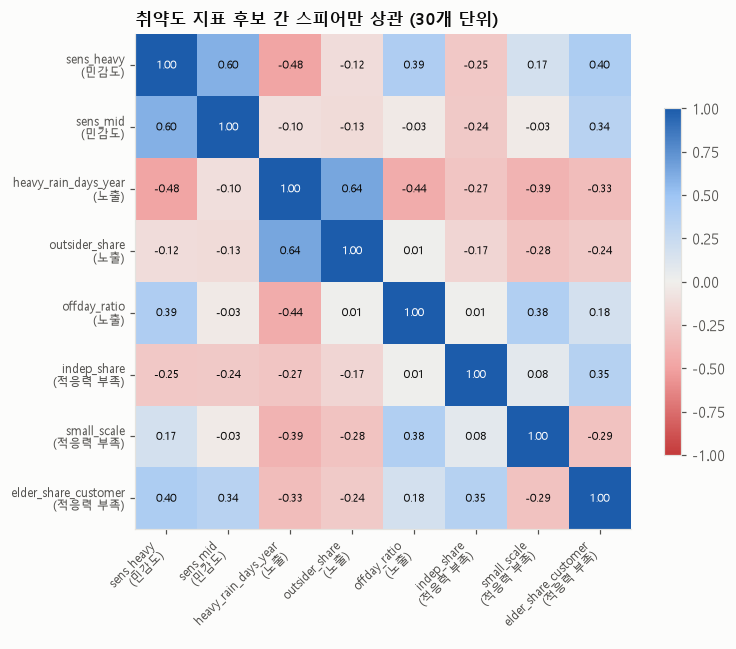

In [11]:
corr = ind[list(INDICATORS)].corr(method='spearman')
fig, ax = plt.subplots(figsize=(7.5, 6))
from matplotlib.colors import LinearSegmentedColormap
DIV = LinearSegmentedColormap.from_list('div', ['#c43a3a', '#f2a3a2', '#f0efec', '#9ec5f4', '#1c5cab'])
im = ax.imshow(corr.values, cmap=DIV, vmin=-1, vmax=1)
labels = [f'{c}\n({INDICATORS[c]})' for c in corr.columns]
ax.set_xticks(range(len(corr)), labels, rotation=45, ha='right', fontsize=8)
ax.set_yticks(range(len(corr)), labels, fontsize=8)
ax.grid(False)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f'{corr.values[i, j]:.2f}', ha='center', va='center', fontsize=7.5,
                color='white' if abs(corr.values[i, j]) > 0.7 else INK)
ax.set_title('취약도 지표 후보 간 스피어만 상관 (30개 단위)', fontsize=11)
fig.colorbar(im, ax=ax, shrink=0.7)
fig.tight_layout()

X = ind[list(INDICATORS)].astype(float)
X = (X - X.mean()) / X.std()
X.insert(0, 'const', 1.0)
vif = pd.Series([variance_inflation_factor(X.values, i + 1) for i in range(len(INDICATORS))], index=list(INDICATORS), name='VIF')
high = [(a, b, round(corr.loc[a, b], 2)) for i, a in enumerate(corr.columns) for b in corr.columns[i + 1:] if abs(corr.loc[a, b]) >= 0.7]
print('|ρ| ≥ 0.7 인 지표 쌍:', high or '없음')
vif.round(2).to_frame().T

- |ρ| ≥ 0.7인 지표 쌍은 없고 VIF도 모두 3 미만이다 → 8개 지표는 서로 다른 정보를 담고 있어 **중복 제거 없이 4단계 후보로 넘긴다.**
- `heavy_rain_days_year`는 지역 단위 값(강남 13.0일·춘천 12.0일)이라 업종 간 차이를 만들지 못하고, **강남이 오히려 더 많아 피해 순서(춘천 > 강남)와 반대**다 (민감도와 ρ = −0.48). '비가 얼마나 자주 오나'만으로는 취약성을 설명하지 못한다는 뜻이며, 4단계에서 이 지표의 포함 여부를 지수 불확실성 분석의 한 선택지로 둔다.
- 민감도 지표(`sens_heavy`)는 01의 **인과 추정치**다. 단순 비교가 아니라 계절·요일 교란을 걷어낸 값이라, 지수의 '민감도'가 기후가 아닌 계절을 측정하는 문제를 피한다.

## 9. 최종 점검·저장

In [12]:
out = df.copy()
checks = {
    '행 수 = 184일 × 2지역 × 15업종': len(out) == 184 * 2 * 15,
    '키 중복 없음': not out.duplicated(['date', 'region', 'industry_group']).any(),
    '매출 합계 보존': out['amount'].sum() == base['amount'].sum(),
    '시차 변수: 1일 전 강한 비 = 전날 rain_heavy': bool(
        (out.sort_values(KEYS + ['date']).groupby(KEYS)['rain_heavy'].shift(1).dropna().values
         == out.sort_values(KEYS + ['date'])['rain_heavy_lag1'].dropna().values).all()),
    'roll28은 당일 매출을 포함하지 않음': bool(np.allclose(
        out.sort_values(KEYS + ['date']).groupby(KEYS)['log_amt'].transform(lambda s: s.shift(1).rolling(28).mean()).dropna(),
        out.sort_values(KEYS + ['date'])['roll28'].dropna())),
    '학습 사용 행(use_for_model)에 기본 입력 결측 없음': out.loc[out['use_for_model'], ['lag7', 'lag14', 'roll7', 'rain_heavy_lag7']].notna().all().all(),
    '원-핫 합 ≤ 1 (기상 유형)': (out[[c for c in out.columns if c.startswith('wt_')]].sum(axis=1) <= 1).all(),
    '단위 지표 30개·결측 없음': len(ind) == 30 and ind[list(INDICATORS)].notna().all().all(),
}
for k, ok in checks.items():
    print(f"[{'OK' if ok else '실패'}] {k}")
assert all(checks.values())
print(f"\nroll28 결측(기간 첫 28일): {out['roll28'].isna().sum()}행 → 3단계에서 roll28을 쓰면 학습 시작일이 7/29로 늦춰진다 (사용 여부는 3단계 교차검증으로 결정)")

[OK] 행 수 = 184일 × 2지역 × 15업종
[OK] 키 중복 없음
[OK] 매출 합계 보존
[OK] 시차 변수: 1일 전 강한 비 = 전날 rain_heavy
[OK] roll28은 당일 매출을 포함하지 않음
[OK] 학습 사용 행(use_for_model)에 기본 입력 결측 없음
[OK] 원-핫 합 ≤ 1 (기상 유형)
[OK] 단위 지표 30개·결측 없음

roll28 결측(기간 첫 28일): 840행 → 3단계에서 roll28을 쓰면 학습 시작일이 7/29로 늦춰진다 (사용 여부는 3단계 교차검증으로 결정)


In [13]:
out.to_parquet(PROC / 'features_daily.parquet', index=False)
ind.to_parquet(PROC / 'unit_indicators.parquet', index=False)
fd = pd.DataFrame([(k, v[0], v[1]) for k, v in NEW.items()], columns=['feature', 'group', 'description'])
fd = pd.concat([fd, pd.DataFrame([(k, '취약도 지표 후보 · ' + v, '') for k, v in INDICATORS.items()],
                                 columns=['feature', 'group', 'description'])], ignore_index=True)
fd.loc[fd['feature'] == 'sens_heavy', 'description'] = '강한 비 인과 피해율(%, 01 경험적 베이즈 축소) — 클수록 취약'
fd.loc[fd['feature'] == 'sens_mid', 'description'] = '보통 비 인과 피해율(%, 01 축소)'
fd.loc[fd['feature'] == 'heavy_rain_days_year', 'description'] = '연평균 강한 비(30mm↑) 일수, 2015~2024 (지역 단위)'
fd.loc[fd['feature'] == 'outsider_share', 'description'] = '외지 고객 매출 비중 (unit_profile)'
fd.loc[fd['feature'] == 'offday_ratio', 'description'] = '휴일/평일 일평균 매출 비 (unit_profile)'
fd.loc[fd['feature'] == 'indep_share', 'description'] = '독립점포 비중 = 1 − 체인 비중 (상가정보)'
fd.loc[fd['feature'] == 'small_scale', 'description'] = '−log(점포당 월매출) — 클수록 작은 점포'
fd.loc[fd['feature'] == 'elder_share_customer', 'description'] = '60대 이상 고객 매출 비중'
fd.to_csv(REF / 'feature_dictionary_cda.csv', index=False, encoding='utf-8-sig')
print(f"features_daily {out.shape} | unit_indicators {ind.shape} | 추가 변수 사전 {len(fd)}개 → references/feature_dictionary_cda.csv")
print('기존 변수 79개의 정의는 eda_analysis/references/feature_dictionary.csv 참고')
fd.groupby('group').size().rename('변수 수').to_frame().T

features_daily (5520, 115) | unit_indicators (30, 21) | 추가 변수 사전 44개 → references/feature_dictionary_cda.csv
기존 변수 79개의 정의는 eda_analysis/references/feature_dictionary.csv 참고


group,기상 시차,달력 레이블,레이블,매출 수준,상호작용,위약 전용,인코딩,취약도 지표 후보 · 노출,취약도 지표 후보 · 민감도,취약도 지표 후보 · 적응력 부족
변수 수,15,4,3,2,3,3,6,3,2,3


## 정리

| 구분 | 결과 |
|---|---|
| 필요성 | 01 인과추론 결과(호우 중심·휴가철 교란·지역/외지 이질성·단위 인과 효과)를 예측·지수·최적화 입력으로 옮기기 위해 **필요** |
| 기상 시차·사건 | 강한 비·보통 비 시차 1~7일, 위약용 선행 1~3일(예측 입력 금지), 경과일, **호우 사건 ID** |
| 교란 대체 통제 | roll14·roll28, 하계휴가 집중기·연휴(전후) 레이블. 춘천은 주 고정효과 결과와 비슷하지만 **강남은 다 걷어내지 못함**(강한 비 −3.8% vs 기준선 −0.4%) → 3단계에서 인과 추정치로 보정 |
| 인코딩 | 단위 30개 정수 코드, 기상 유형 원-핫, 지역·외지 × 강한 비 상호작용. 목표 인코딩 미사용 |
| 레이블링 | 단위 피해 등급(확인된 피해 9개: 춘천 7·강남 2 / 경미·불확실 15개 / 영향 없음 6개), 지원 자격(대형유통 제외) |
| 스케일링 | 저장 안 함. 트리·OLS는 미적용, LASSO는 파이프라인 안에서 학습 블록만 fit, 지수 지표는 4단계에서 변환 방식 비교 |
| 누수 점검 | 구조 변수는 7~9월·10~12월로 나눠도 업종 순위 상관 0.97~1.00 → 고정값 사용 가능 |
| 취약도 지표 후보 | 민감도(인과 피해율)·노출(외지 비중·휴일 의존·강한 비 빈도)·적응력 부족(독립점포·소규모·고령 고객) 8개 |
| 산출물 | `features_daily.parquet`, `unit_indicators.parquet`, `references/feature_dictionary_cda.csv` |
| 다음 단계 | **03 피해 예측** — 논문(Roth Tran, 2023 등) 근거의 반사실 피해 예측, 기간 간 대체를 반영한 순손실 |

### 참고문헌
- Roth Tran, B. (2023). Sellin' in the Rain: Weather, Climate, and Retail Sales. *Management Science*, 69(12). — 날씨 시차·선행 변수와 기간 간 대체
- Tate, E. (2012). Social vulnerability indices: a comparative assessment using uncertainty and sensitivity analysis. *Natural Hazards*, 63(2), 325–347. — 지수 구성의 변환·가중 선택이 순위를 바꾼다
- IPCC (2007). *Climate Change 2007: Impacts, Adaptation and Vulnerability* (WG II). — 취약성 = 노출 · 민감도 · 적응력
- Turner, B. L. et al. (2003). A framework for vulnerability analysis in sustainability science. *PNAS*, 100(14), 8074–8079.